In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
# Define dataset directory
DATA_PATH = Path("C:\\Users\\NEHA KATUWAL\\Desktop\\Nepal_Agriculture_Analysis\\csv_source_files")

# Load all CSV files
datasets = {
    file.stem: pd.read_csv(file)
    for file in DATA_PATH.glob("*.csv")
}

print(f"Total datasets loaded: {len(datasets)}")

Total datasets loaded: 13


In [3]:
for name, df in datasets.items():
    print(f"{name}: {df.shape}")

01_cereal_crops_yearly: (66, 5)
02_cereal_production_by_province_2024_25: (48, 4)
03_cereal_production_by_district_2024_25: (85, 7)
04_major_cash_crops_yearly: (50, 5)
05_major_cash_crops_by_province_2024_25: (24, 6)
06_pulses_yearly: (120, 5)
07_livestock_population_yearly: (110, 3)
08_livestock_products_yearly: (150, 3)
09_major_fruits_yearly: (40, 6)
10_fresh_vegetables_yearly: (10, 4)
11_fresh_vegetables_by_province_2024_25: (7, 5)
12_chemical_fertilizer_sales_yearly: (15, 5)
13_agriculture_gdp_commodity_contribution_2024_25: (93, 2)


In [4]:
for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(f"Dataset: {name}")
    print(f"Columns: {df.columns.tolist()}")
    print(df.head(3))


Dataset: 01_cereal_crops_yearly
Columns: ['Fiscal_Year', 'Crop', 'Area_Ha', 'Production_Mt', 'Yield_Mt_per_Ha']
  Fiscal_Year    Crop  Area_Ha  Production_Mt  Yield_Mt_per_Ha
0     2014/15  Barley    28053          37354             1.33
1     2015/16  Barley    28361          32801             1.16
2     2016/17  Barley    27370          30510             1.11

Dataset: 02_cereal_production_by_province_2024_25
Columns: ['Fiscal_Year', 'Province', 'Crop', 'Production_Mt']
  Fiscal_Year Province       Crop  Production_Mt
0     2024/25    Koshi  Buckwheat         4775.0
1     2024/25  Madhesh  Buckwheat            NaN
2     2024/25  Bagmati  Buckwheat         3260.0

Dataset: 03_cereal_production_by_district_2024_25
Columns: ['Fiscal_Year', 'Province', 'District', 'Area_Ha', 'Production_Mt', 'Yield_Mt_per_Ha', 'Row_Type']
  Fiscal_Year Province       District  Area_Ha  Production_Mt  \
0     2024/25    KOSHI      TAPLEJUNG    21673          63863   
1     2024/25    KOSHI  SANKHUWASABHA

In [5]:
missing_summary = pd.DataFrame({
    name: {
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    }
    for name, df in datasets.items()
}).T

display(missing_summary)

,Rows,Columns,Missing Values,Duplicate Rows
01_cereal_crops_yearly,66,5,0,0
02_cereal_production_by_province_2024_25,48,4,1,0
03_cereal_production_by_district_2024_25,85,7,0,0
04_major_cash_crops_yearly,50,5,0,0
05_major_cash_crops_by_province_2024_25,24,6,0,0
06_pulses_yearly,120,5,27,0
07_livestock_population_yearly,110,3,0,0
08_livestock_products_yearly,150,3,1,0
09_major_fruits_yearly,40,6,0,0
10_fresh_vegetables_yearly,10,4,0,0


In [ ]:
# How has Nepal's cereal production changed over the last 11 fiscal years, and is production growth associated with increasing cultivated area or improving yield? 


# Select cereal production dataset
cereal_df = datasets["01_cereal_crops_yearly"]

# Aggregate production and cultivated area by fiscal year
cereal_trend = (
    cereal_df.groupby("Fiscal_Year", as_index=False)
    .agg(
        Total_Area_Ha=("Area_Ha", "sum"),
        Total_Production_Mt=("Production_Mt", "sum")
    )
)

# Calculate weighted average yield
cereal_trend["Average_Yield_Mt_per_Ha"] = (
    cereal_trend["Total_Production_Mt"] /
    cereal_trend["Total_Area_Ha"]
)

# Calculate year-over-year growth
cereal_trend["Production_Growth_%"] = (
    cereal_trend["Total_Production_Mt"].pct_change() * 100
)

cereal_trend["Area_Growth_%"] = (
    cereal_trend["Total_Area_Ha"].pct_change() * 100
)

cereal_trend["Yield_Growth_%"] = (
    cereal_trend["Average_Yield_Mt_per_Ha"].pct_change() * 100
)

# Display results
display(cereal_trend.round(2))

,Fiscal_Year,Total_Area_Ha,Total_Production_Mt,Average_Yield_Mt_per_Ha,Production_Growth_%,Area_Growth_%,Yield_Growth_%
0,2014/15,877036,5966240,6.80,NaN,NaN,NaN
1,2015/16,806316,5314284,6.59,-10.93,-8.06,-3.12
2,2016/17,1590663,9758892,6.14,83.64,97.28,-6.91
3,2017/18,1528987,10012742,6.55,2.60,-3.88,6.74
4,2018/19,850164,6385550,7.51,-36.23,-44.40,14.70
5,2019/20,1521390,10935665,7.19,71.26,78.95,-4.30
6,2020/21,2565455,11118512,4.33,1.67,68.63,-39.71
7,2021/22,1586249,10772498,6.79,-3.11,-38.17,56.70
8,2022/23,2443134,10913266,4.47,1.31,54.02,-34.22
9,2023/24,3291671,11293841,3.43,3.49,34.73,-23.19


In [7]:
# Validate reported production against area and yield

cereal_validation = cereal_df.copy()

cereal_validation["Calculated_Production"] = (
    cereal_validation["Area_Ha"] *
    cereal_validation["Yield_Mt_per_Ha"]
)

cereal_validation["Difference_%"] = (
    (
        cereal_validation["Production_Mt"] -
        cereal_validation["Calculated_Production"]
    ).abs()
    / cereal_validation["Production_Mt"].abs()
) * 100

# Flag records with more than 5% difference
cereal_validation["Data_Issue"] = (
    cereal_validation["Difference_%"] > 5
)

# Show inconsistent records
inconsistent_records = (
    cereal_validation[cereal_validation["Data_Issue"]]
    .sort_values("Difference_%", ascending=False)
)

display(
    inconsistent_records[
        [
            "Fiscal_Year",
            "Crop",
            "Area_Ha",
            "Production_Mt",
            "Yield_Mt_per_Ha",
            "Calculated_Production",
            "Difference_%"
        ]
    ].round(2)
)

print("Total inconsistent records:", len(inconsistent_records))

,Fiscal_Year,Crop,Area_Ha,Production_Mt,Yield_Mt_per_Ha,Calculated_Production,Difference_%
34,2015/16,Millet,266799,2397,1.13,301482.87,12477.51
33,2014/15,Millet,268050,8488,1.15,308257.50,3531.69
37,2018/19,Millet,263261,14225,1.19,313280.59,2102.32
15,2018/19,Wheat,3992,5665,2.85,11377.20,100.83
46,2016/17,Maize,288,2300121,2.55,734.40,99.97
52,2022/23,Maize,40256,2976490,3.17,127611.52,95.71
47,2017/18,Maize,54158,2555847,2.68,145143.44,94.32
49,2019/20,Maize,57650,2835674,2.96,170644.00,93.98
50,2020/21,Maize,79776,2997733,3.06,244114.56,91.86
51,2021/22,Maize,85565,3106397,3.15,269529.75,91.32


Total inconsistent records: 21


In [8]:
# Inspect original records
display(cereal_df.head(15))

,Fiscal_Year,Crop,Area_Ha,Production_Mt,Yield_Mt_per_Ha
0,2014/15,Barley,28053,37354,1.33
1,2015/16,Barley,28361,32801,1.16
2,2016/17,Barley,27370,30510,1.11
3,2017/18,Barley,24648,30510,1.24
4,2018/19,Barley,24409,30550,1.25
5,2019/20,Barley,24404,31147,1.28
6,2020/21,Barley,21862,29433,1.35
7,2021/22,Barley,23134,32156,1.39
8,2022/23,Barley,17536,25912,1.48
9,2023/24,Barley,18599,24931,1.34


In [9]:
# Inspect numerical statistics
display(cereal_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Area_Ha,66.0,3.078871e+05,3.929246e+05,288.00,22180.0000,88574.000,4.754198e+05,1473474.00
Production_Mt,66.0,1.576949e+06,1.980295e+06,2397.00,25176.2500,317470.000,2.765717e+06,5955476.00
Yield_Mt_per_Ha,66.0,2.186515e+00,1.025886e+00,1.01,1.2325,1.905,3.047500e+00,4.19


In [11]:
# Summarize validation issues by crop

crop_issue_summary = (
    cereal_validation
    .groupby("Crop")
    .agg(
        Total_Records=("Crop", "size"),
        Inconsistent_Records=("Data_Issue", "sum"),
        Average_Difference_Pct=("Difference_%", "mean")
    )
    .reset_index()
)

crop_issue_summary["Issue_Rate_%"] = (
    crop_issue_summary["Inconsistent_Records"] /
    crop_issue_summary["Total_Records"] * 100
)

display(crop_issue_summary.round(2))

,Crop,Total_Records,Inconsistent_Records,Average_Difference_Pct,Issue_Rate_%
0,Barley,11,0,0.19,0.00
1,Buckwheat,11,0,0.25,0.00
2,Maize,11,8,62.16,72.73
3,Millet,11,3,1646.64,27.27
4,Paddy,11,7,43.60,63.64
5,Wheat,11,3,24.60,27.27


In [12]:
# Display all inconsistent crop-year records

display(
    inconsistent_records[
        [
            "Fiscal_Year",
            "Crop",
            "Area_Ha",
            "Production_Mt",
            "Yield_Mt_per_Ha",
            "Calculated_Production",
            "Difference_%"
        ]
    ].sort_values(["Crop", "Fiscal_Year"])
)

,Fiscal_Year,Crop,Area_Ha,Production_Mt,Yield_Mt_per_Ha,Calculated_Production,Difference_%
44,2014/15,Maize,82395,145291,2.43,200219.85,37.806093
46,2016/17,Maize,288,2300121,2.55,734.40,99.968071
47,2017/18,Maize,54158,2555847,2.68,145143.44,94.321122
48,2018/19,Maize,56447,713635,2.84,160309.48,77.536208
49,2019/20,Maize,57650,2835674,2.96,170644.00,93.982242
50,2020/21,Maize,79776,2997733,3.06,244114.56,91.856694
51,2021/22,Maize,85565,3106397,3.15,269529.75,91.323397
52,2022/23,Maize,40256,2976490,3.17,127611.52,95.712684
33,2014/15,Millet,268050,8488,1.15,308257.50,3531.685910
34,2015/16,Millet,266799,2397,1.13,301482.87,12477.508135


In [13]:
# Calculate production-to-calculated-production ratio

cereal_validation["Production_Ratio"] = (
    cereal_validation["Production_Mt"] /
    cereal_validation["Calculated_Production"]
)

ratio_summary = (
    cereal_validation
    .groupby("Crop")
    .agg(
        Median_Ratio=("Production_Ratio", "median"),
        Minimum_Ratio=("Production_Ratio", "min"),
        Maximum_Ratio=("Production_Ratio", "max"),
        Records=("Production_Ratio", "count")
    )
    .round(2)
)

display(ratio_summary)

,Median_Ratio,Minimum_Ratio,Maximum_Ratio,Records
Crop,,,,
Barley,1.00,1.00,1.00,11
Buckwheat,1.00,0.99,1.00,11
Maize,11.53,0.73,3131.97,11
Millet,1.00,0.01,1.00,11
Paddy,3.03,1.00,3.76,11
Wheat,1.00,0.50,6.90,11


In [14]:
# Calculate total production by crop

crop_production = (
    cereal_df.groupby("Crop")
    .agg(
        Total_Production_Mt=("Production_Mt", "sum"),
        Average_Production_Mt=("Production_Mt", "mean"),
        Total_Records=("Production_Mt", "count")
    )
    .reset_index()
)

# Calculate contribution percentage
crop_production["Production_Share_%"] = (
    crop_production["Total_Production_Mt"]
    / crop_production["Total_Production_Mt"].sum()
) * 100

# Rank crops by production
crop_production = crop_production.sort_values(
    "Total_Production_Mt",
    ascending=False
).reset_index(drop=True)

crop_production.insert(
    0, "Rank", range(1, len(crop_production) + 1)
)

display(crop_production.round(2))

,Rank,Crop,Total_Production_Mt,Average_Production_Mt,Total_Records,Production_Share_%
0,1,Paddy,58549349,5322668.09,11,56.25
1,2,Maize,24332166,2212015.09,11,23.38
2,3,Wheat,18193296,1653936.00,11,17.48
3,4,Millet,2528590,229871.82,11,2.43
4,5,Barley,327558,29778.00,11,0.31
5,6,Buckwheat,147652,13422.91,11,0.14


In [15]:
# Annual production comparison by crop

annual_crop_production = (
    cereal_df.pivot_table(
        index="Fiscal_Year",
        columns="Crop",
        values="Production_Mt",
        aggfunc="sum"
    )
)

display(annual_crop_production.round(2))

Crop,Barley,Buckwheat,Maize,Millet,Paddy,Wheat
Fiscal_Year,,,,,,
2014/15,37354,10870,145291,8488,4788612,975625
2015/16,32801,11641,231517,2397,4299079,736849
2016/17,30510,12039,2300121,306704,5230327,1879191
2017/18,30510,11472,2555847,313987,5151925,1949001
2018/19,30550,11464,713635,14225,5610011,5665
2019/20,31147,11724,2835674,320953,5550878,2185289
2020/21,29433,15917,2997733,326443,5621710,2127276
2021/22,32156,19290,3106397,339462,5130625,2144568
2022/23,25912,15083,2976490,310847,5486472,2098462


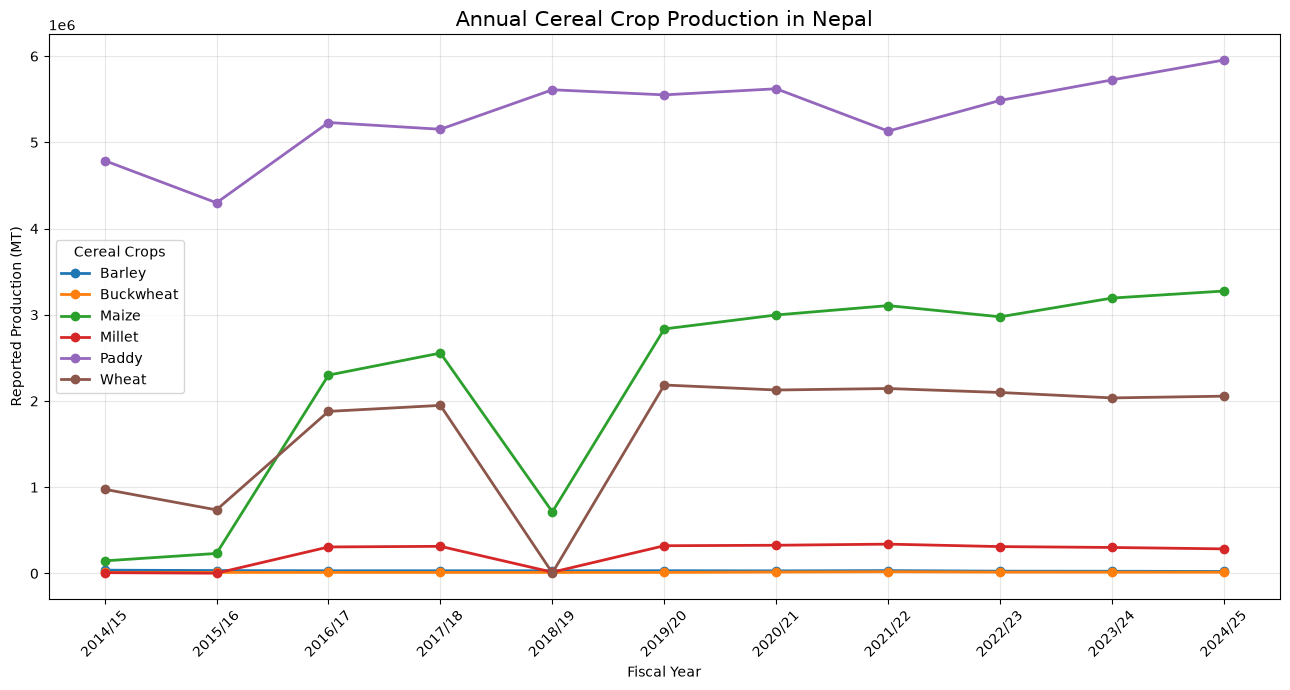

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 7))

for crop in annual_crop_production.columns:
    plt.plot(
        annual_crop_production.index,
        annual_crop_production[crop],
        marker="o",
        linewidth=2,
        label=crop
    )

plt.title("Annual Cereal Crop Production in Nepal", fontsize=15)
plt.xlabel("Fiscal Year")
plt.ylabel("Reported Production (MT)")
plt.xticks(rotation=45)
plt.legend(title="Cereal Crops")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Major Cash Crops

In [17]:
cash_crop_df = datasets["04_major_cash_crops_yearly"]

print("Shape:", cash_crop_df.shape)
display(cash_crop_df.head())
print("\nColumns:")
print(cash_crop_df.dtypes)


Shape: (50, 5)


,Fiscal_Year,Crop,Area_Ha,Production_Mt,Yield_Mt_per_Ha
0,2015/16,Cotton,125,129,1.03
1,2016/17,Cotton,143,127,0.89
2,2017/18,Cotton,120,125,1.04
3,2018/19,Cotton,97,99,1.02
4,2019/20,Cotton,135,140,1.02



Columns:
Fiscal_Year            str
Crop                   str
Area_Ha              int64
Production_Mt        int64
Yield_Mt_per_Ha    float64
dtype: object


In [18]:
print("Total records:", len(cash_crop_df))

print("\nCrops:")
print(cash_crop_df["Crop"].unique())

print("\nFiscal years:")
print(sorted(cash_crop_df["Fiscal_Year"].unique()))

print("\nRecords per crop:")
display(cash_crop_df.groupby("Crop").size().reset_index(name="Records"))

Total records: 50

Crops:
<StringArray>
['Cotton', 'Jute', 'Sugarcane', 'Potato', 'Oilseed']
Length: 5, dtype: str

Fiscal years:
['2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23', '2023/24', '2024/25']

Records per crop:


,Crop,Records
0,Cotton,10
1,Jute,10
2,Oilseed,10
3,Potato,10
4,Sugarcane,10


In [19]:
cash_crop_summary = (
    cash_crop_df.groupby("Crop")
    .agg(
        Total_Production_Mt=("Production_Mt", "sum"),
        Average_Production_Mt=("Production_Mt", "mean"),
        Total_Area_Ha=("Area_Ha", "sum"),
        Average_Yield=("Yield_Mt_per_Ha", "mean")
    )
    .reset_index()
)

cash_crop_summary["Production_Share_%"] = (
    cash_crop_summary["Total_Production_Mt"]
    / cash_crop_summary["Total_Production_Mt"].sum()
) * 100

cash_crop_summary = cash_crop_summary.sort_values(
    "Total_Production_Mt", ascending=False
)

display(cash_crop_summary.round(2))

,Crop,Total_Production_Mt,Average_Production_Mt,Total_Area_Ha,Average_Yield,Production_Share_%
4,Sugarcane,33132163,3313216.3,669243,49.52,48.72
3,Potato,32157232,3215723.2,1996173,16.09,47.29
2,Oilseed,2608086,260808.6,2420125,1.00,3.84
1,Jute,105778,10577.8,74101,1.44,0.16
0,Cotton,1074,107.4,1046,1.03,0.00


In [20]:
cash_crop_trend = cash_crop_df.pivot(
    index="Fiscal_Year",
    columns="Crop",
    values="Production_Mt"
)

display(cash_crop_trend)

Crop,Cotton,Jute,Oilseed,Potato,Sugarcane
Fiscal_Year,,,,,
2015/16,129,11633,208291,2805582,4346754
2016/17,127,11018,214451,2591686,3219560
2017/18,125,11159,245867,3088000,3679508
2018/19,99,10585,280530,3112947,3557934
2019/20,140,10165,278325,3131830,3400176
2020/21,147,10451,287038,3325231,3183943
2021/22,172,10217,287344,3410829,3159634
2022/23,65,10205,270482,3487816,3130109
2023/24,56,10220,262561,3521794,2760495


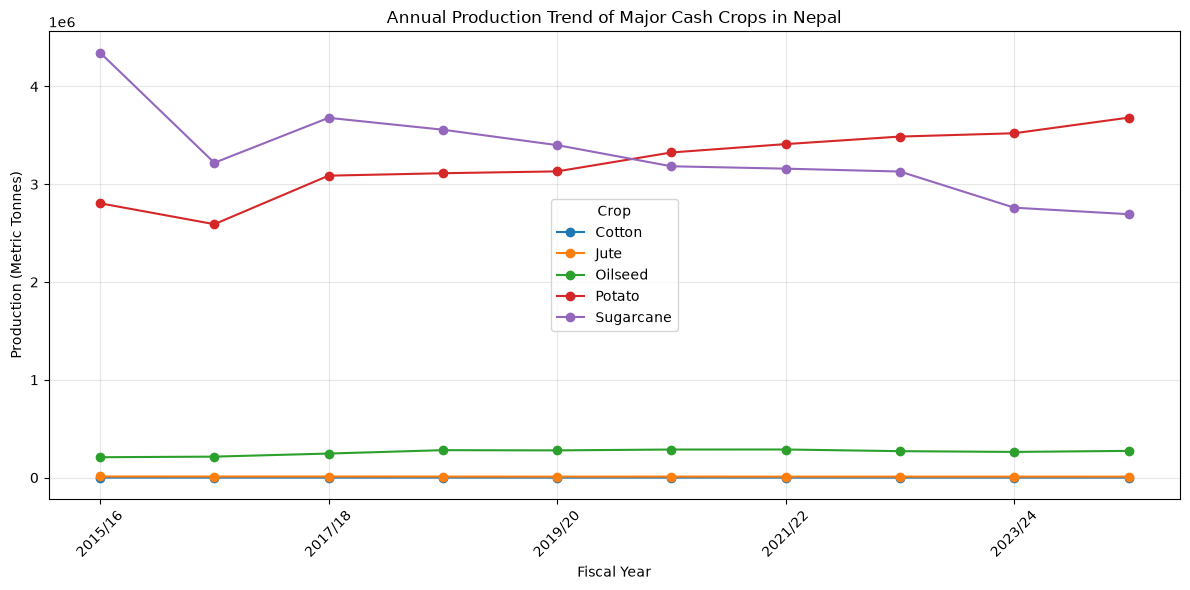

In [21]:
cash_crop_trend.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Annual Production Trend of Major Cash Crops in Nepal")
plt.xlabel("Fiscal Year")
plt.ylabel("Production (Metric Tonnes)")
plt.xticks(rotation=45)
plt.legend(title="Crop")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
cash_crop_yield = (
    cash_crop_df.groupby("Crop")
    .agg(
        Average_Yield=("Yield_Mt_per_Ha", "mean"),
        Minimum_Yield=("Yield_Mt_per_Ha", "min"),
        Maximum_Yield=("Yield_Mt_per_Ha", "max")
    )
    .reset_index()
    .sort_values("Average_Yield", ascending=False)
)

display(cash_crop_yield.round(2))

,Crop,Average_Yield,Minimum_Yield,Maximum_Yield
4,Sugarcane,49.52,45.47,53.71
3,Potato,16.09,13.94,17.20
1,Jute,1.44,1.41,1.47
0,Cotton,1.03,0.89,1.11
2,Oilseed,1.00,0.78,1.11


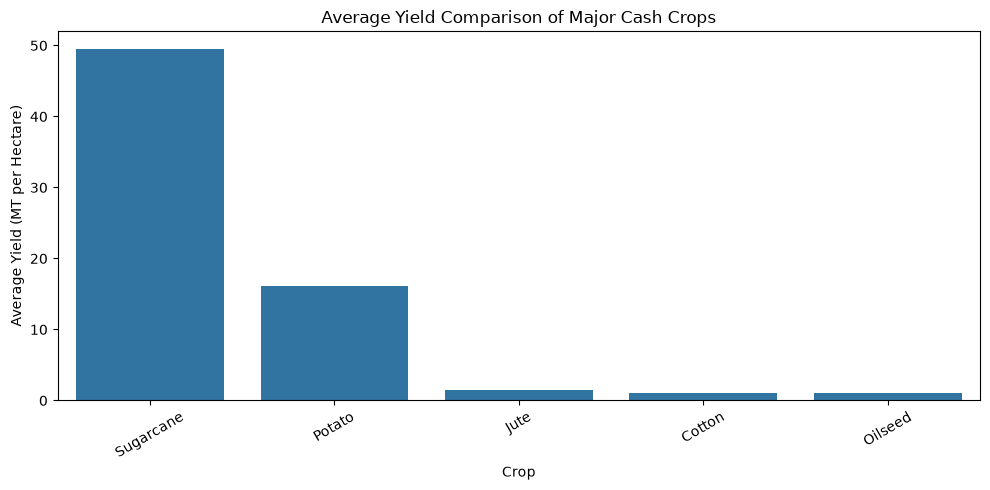

In [23]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cash_crop_yield,
    x="Crop",
    y="Average_Yield"
)

plt.title("Average Yield Comparison of Major Cash Crops")
plt.xlabel("Crop")
plt.ylabel("Average Yield (MT per Hectare)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Major pulses


In [24]:
pulses_df = datasets["06_pulses_yearly"]

print("Shape:", pulses_df.shape)
display(pulses_df.head())

print("\nData types:")
print(pulses_df.dtypes)

Shape: (120, 5)


,Fiscal_Year,Crop,Area_Ha,Production_Mt,Yield_Kg_per_Ha
0,2013/14,Grass Pea,11495.0,14103.0,1227.0
1,2014/15,Grass Pea,11413.0,14144.0,1239.0
2,2015/16,Grass Pea,8075.0,9354.0,1239.0
3,2016/17,Grass Pea,8075.0,9354.0,1239.0
4,2017/18,Grass Pea,7757.0,9187.0,1184.0



Data types:
Fiscal_Year            str
Crop                   str
Area_Ha            float64
Production_Mt      float64
Yield_Kg_per_Ha    float64
dtype: object


In [25]:
print("Number of pulse crops:", pulses_df["Crop"].nunique())

print("\nPulse crops:")
print(sorted(pulses_df["Crop"].unique()))

print("\nFiscal years:")
print(sorted(pulses_df["Fiscal_Year"].unique()))

print("\nRecords per crop:")
display(
    pulses_df.groupby("Crop")
    .agg(
        Records=("Fiscal_Year", "count"),
        First_Year=("Fiscal_Year", "min"),
        Last_Year=("Fiscal_Year", "max")
    )
    .reset_index()
)

Number of pulse crops: 10

Pulse crops:
['Black Gram', 'Chickpea', 'Grass Pea', 'Himili Bean', 'Horse Gram', 'Lentil', 'Others +', 'Pigeon Pea', 'Soyabean', 'Total']

Fiscal years:
['2013/14', '2014/15', '2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23', '2023/24', '2024/25']

Records per crop:


,Crop,Records,First_Year,Last_Year
0,Black Gram,12,2013/14,2024/25
1,Chickpea,12,2013/14,2024/25
2,Grass Pea,12,2013/14,2024/25
3,Himili Bean,12,2013/14,2024/25
4,Horse Gram,12,2013/14,2024/25
5,Lentil,12,2013/14,2024/25
6,Others +,12,2013/14,2024/25
7,Pigeon Pea,12,2013/14,2024/25
8,Soyabean,12,2013/14,2024/25
9,Total,12,2013/14,2024/25


In [26]:
pulses_analysis = pulses_df[
    pulses_df["Crop"] != "Total"
].copy()

print("Original records:", len(pulses_df))
print("Records after excluding Total:", len(pulses_analysis))

print("\nRemaining crops:")
print(sorted(pulses_analysis["Crop"].unique()))

Original records: 120
Records after excluding Total: 108

Remaining crops:
['Black Gram', 'Chickpea', 'Grass Pea', 'Himili Bean', 'Horse Gram', 'Lentil', 'Others +', 'Pigeon Pea', 'Soyabean']


In [27]:
pulse_summary = (
    pulses_analysis.groupby("Crop")
    .agg(
        Total_Production_Mt=("Production_Mt", "sum"),
        Average_Production_Mt=("Production_Mt", "mean"),
        Total_Area_Ha=("Area_Ha", "sum"),
        Average_Yield_Kg_per_Ha=("Yield_Kg_per_Ha", "mean")
    )
    .reset_index()
)

pulse_summary["Production_Share_%"] = (
    pulse_summary["Total_Production_Mt"]
    / pulse_summary["Total_Production_Mt"].sum()
) * 100

pulse_summary = pulse_summary.sort_values(
    "Total_Production_Mt", ascending=False
)

display(pulse_summary.round(2))

,Crop,Total_Production_Mt,Average_Production_Mt,Total_Area_Ha,Average_Yield_Kg_per_Ha,Production_Share_%
5,Lentil,2718537.0,226544.75,2296053.0,895.01,63.05
6,Others +,416494.0,34707.83,372479.0,836.36,9.66
8,Soyabean,374936.0,31244.67,293325.0,941.22,8.70
0,Black Gram,258704.0,21558.67,293936.0,645.74,6.00
7,Pigeon Pea,184615.0,15384.58,185960.0,742.58,4.28
1,Chickpea,128919.0,10743.25,116586.0,804.19,2.99
2,Grass Pea,115895.0,9657.92,98664.0,899.69,2.69
4,Horse Gram,88248.0,7354.00,86575.0,744.50,2.05
3,Himili Bean,25436.0,8478.67,19795.0,1.20,0.59


In [28]:
pulse_trend = pulses_analysis.pivot(
    index="Fiscal_Year",
    columns="Crop",
    values="Production_Mt"
)

display(pulse_trend)

Crop,Black Gram,Chickpea,Grass Pea,Himili Bean,Horse Gram,Lentil,Others +,Pigeon Pea,Soyabean
Fiscal_Year,,,,,,,,,
2013/14,19383.0,9380.0,14103.0,NaN,5662.0,226830.0,32817.0,16415.0,28237.0
2014/15,19439.0,9408.0,14144.0,NaN,5678.0,227492.0,32913.0,16462.0,28319.0
2015/16,19402.0,10914.0,9354.0,NaN,5662.0,253041.0,32817.0,16415.0,28917.0
2016/17,19499.0,10969.0,9354.0,NaN,5690.0,254308.0,32817.0,16497.0,29061.0
2017/18,20839.0,11271.0,9187.0,NaN,5664.0,249491.0,28397.0,16211.0,27681.0
2018/19,19928.0,10675.0,9329.0,NaN,5754.0,251185.0,37011.0,16538.0,31567.0
2019/20,20440.0,11285.0,9504.0,NaN,6865.0,262835.0,41672.0,17063.0,34544.0
2020/21,21633.0,11065.0,11965.0,NaN,15453.0,246092.0,39320.0,16649.0,32178.0
2021/22,26114.0,12196.0,12072.0,NaN,14330.0,252283.0,40260.0,15977.0,35138.0


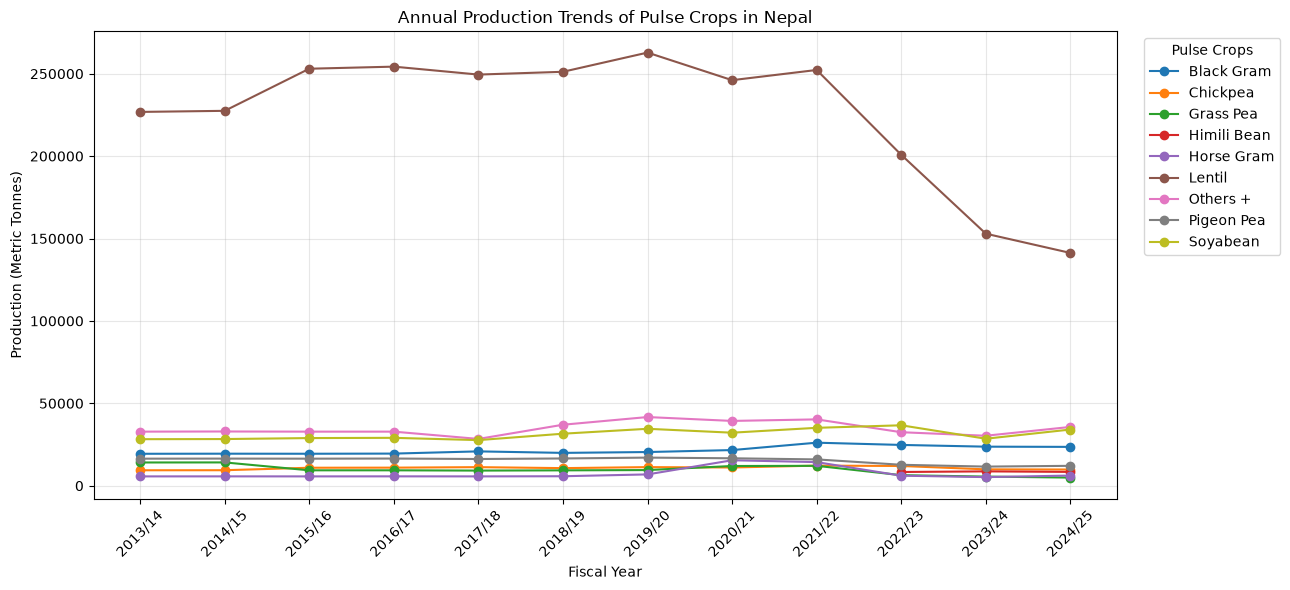

In [29]:
plt.figure(figsize=(13, 6))

for crop in pulse_trend.columns:
    plt.plot(
        pulse_trend.index,
        pulse_trend[crop],
        marker="o",
        label=crop
    )

plt.title("Annual Production Trends of Pulse Crops in Nepal")
plt.xlabel("Fiscal Year")
plt.ylabel("Production (Metric Tonnes)")
plt.xticks(rotation=45)
plt.legend(title="Pulse Crops", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
pulses_analysis["Yield_mt_per_Ha"] = (
    pulses_analysis["Production_Mt"]
    / pulses_analysis["Area_Ha"]
) 

In [37]:
pulse_yield_summary = (
    pulses_analysis.groupby("Crop")
    .agg(
        Average_Yield=("Yield_mt_per_Ha", "mean"),
        Minimum_Yield=("Yield_mt_per_Ha", "min"),
        Maximum_Yield=("Yield_mt_per_Ha", "max"),
        Available_Years=("Yield_mt_per_Ha", "count")
    )
    .reset_index()
    .sort_values("Average_Yield", ascending=False)
)

display(pulse_yield_summary.round(2))

,Crop,Average_Yield,Minimum_Yield,Maximum_Yield,Available_Years
3,Himili Bean,1.28,1.27,1.31,3
8,Soyabean,1.28,1.19,1.41,12
5,Lentil,1.18,1.05,1.27,12
2,Grass Pea,1.17,1.10,1.24,12
6,Others +,1.12,1.07,1.22,12
1,Chickpea,1.10,1.00,1.15,12
7,Pigeon Pea,1.00,0.93,1.08,12
4,Horse Gram,0.99,0.90,1.17,12
0,Black Gram,0.88,0.83,0.94,12


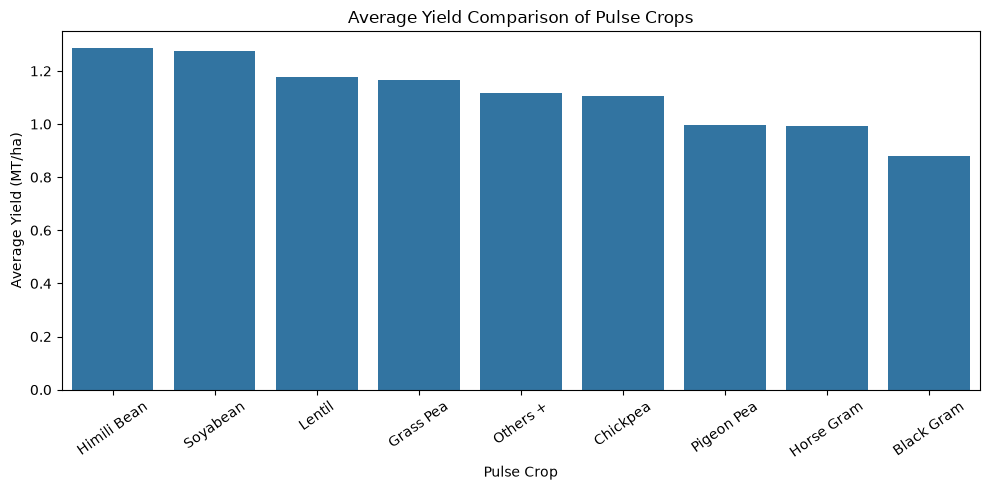

In [41]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=pulse_yield_summary,
    x="Crop",
    y="Average_Yield"
)

plt.title("Average Yield Comparison of Pulse Crops")
plt.xlabel("Pulse Crop")
plt.ylabel("Average Yield (MT/ha)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

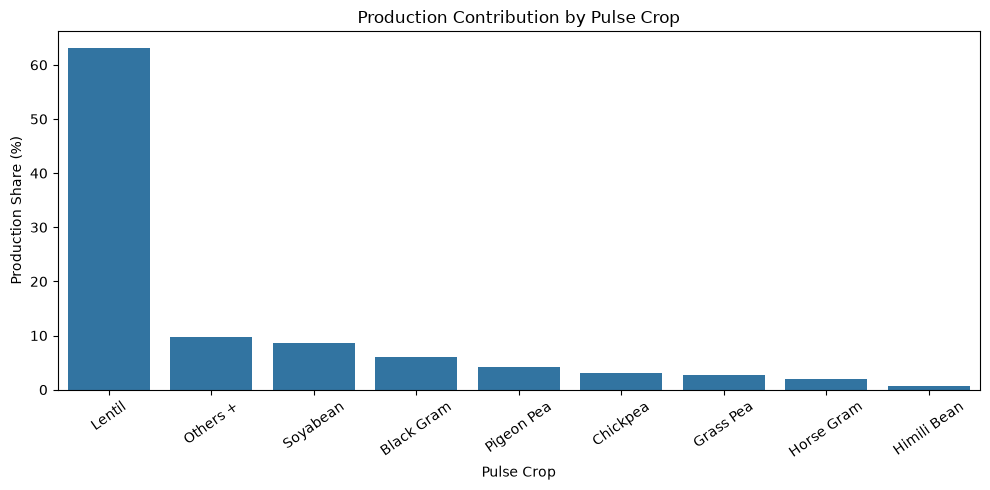

In [42]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=pulse_summary,
    x="Crop",
    y="Production_Share_%"
)

plt.title("Production Contribution by Pulse Crop")
plt.xlabel("Pulse Crop")
plt.ylabel("Production Share (%)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

### Pulses Analysis — Key Findings

- Analyzed nine individual pulse categories across 12 fiscal years (2013/14–2024/25), excluding the aggregate `Total` category.
- Compared cumulative production, average production, cultivated area and production contribution across pulse crops.
- Lentil was the dominant contributor to total reported pulse production.
- Annual production trends revealed fluctuations across different pulse categories, with noticeable changes in Lentil production in recent years.
- Compared crop productivity using calculated yield in MT/ha for consistent units.
- Created visualizations for annual production trends, production contribution and average yield comparison.

### Data Quality and Limitations

- The official `Yield_Kg_per_Ha` column contains inconsistent scaling in some recent records. Calculated yield was used for analysis, while original source values were preserved.
- Himili Bean contains production data for only three fiscal years (2022/23–2024/25), limiting comparisons with other crops.
- `Others +` represents an aggregated category rather than an individual crop.
- Findings are based on the available official data and should be interpreted with these limitations in mind.

### Major Fruits Analysis

In [43]:
fruits_df = datasets["09_major_fruits_yearly"]

print("Shape:", fruits_df.shape)
display(fruits_df.head())

print("\nData types:")
print(fruits_df.dtypes)

Shape: (40, 6)


,Fruit_Group,Fiscal_Year,Total_Area_Ha,Productive_Area_Ha,Production_Mt,Yield_Mt_per_Ha
0,Citrus Fruits,2015/16,40554,24854,218447,8.79
1,Citrus Fruits,2016/17,46328,26759,239773,8.96
2,Citrus Fruits,2017/18,44424,25964,245176,9.44
3,Citrus Fruits,2018/19,46392,28411,272620,9.60
4,Citrus Fruits,2019/20,46715,27339,274140,10.03



Data types:
Fruit_Group               str
Fiscal_Year               str
Total_Area_Ha           int64
Productive_Area_Ha      int64
Production_Mt           int64
Yield_Mt_per_Ha       float64
dtype: object


In [44]:
print("Fruit groups:")
print(fruits_df["Fruit_Group"].unique())

print("\nFiscal years:")
print(sorted(fruits_df["Fiscal_Year"].unique()))

print("\nRecords per fruit group:")
display(
    fruits_df.groupby("Fruit_Group")
    .agg(
        Records=("Fiscal_Year", "count"),
        First_Year=("Fiscal_Year", "min"),
        Last_Year=("Fiscal_Year", "max")
    )
    .reset_index()
)

Fruit groups:
<StringArray>
['Citrus Fruits', 'Winter Fruits', 'Summer Fruits', 'Total Fruits']
Length: 4, dtype: str

Fiscal years:
['2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23', '2023/24', '2024/25']

Records per fruit group:


,Fruit_Group,Records,First_Year,Last_Year
0,Citrus Fruits,10,2015/16,2024/25
1,Summer Fruits,10,2015/16,2024/25
2,Total Fruits,10,2015/16,2024/25
3,Winter Fruits,10,2015/16,2024/25


In [45]:
fruits_analysis = fruits_df[
    fruits_df["Fruit_Group"] != "Total Fruits"
].copy()

print("Original records:", len(fruits_df))
print("Analysis records:", len(fruits_analysis))

print("\nFruit groups included:")
print(fruits_analysis["Fruit_Group"].unique())

Original records: 40
Analysis records: 30

Fruit groups included:
<StringArray>
['Citrus Fruits', 'Winter Fruits', 'Summer Fruits']
Length: 3, dtype: str


In [46]:
fruit_summary = (
    fruits_analysis.groupby("Fruit_Group")
    .agg(
        Total_Production_Mt=("Production_Mt", "sum"),
        Average_Production_Mt=("Production_Mt", "mean"),
        Total_Area_Ha=("Total_Area_Ha", "sum"),
        Total_Productive_Area_Ha=("Productive_Area_Ha", "sum"),
        Average_Yield_Mt_per_Ha=("Yield_Mt_per_Ha", "mean")
    )
    .reset_index()
)

fruit_summary["Production_Share_%"] = (
    fruit_summary["Total_Production_Mt"]
    / fruit_summary["Total_Production_Mt"].sum()
) * 100

fruit_summary = fruit_summary.sort_values(
    "Total_Production_Mt", ascending=False
)

display(fruit_summary.round(2))

,Fruit_Group,Total_Production_Mt,Average_Production_Mt,Total_Area_Ha,Total_Productive_Area_Ha,Average_Yield_Mt_per_Ha,Production_Share_%
1,Summer Fruits,8743247,874324.7,943907,780609,11.12,68.15
0,Citrus Fruits,2827147,282714.7,470322,300850,9.39,22.04
2,Winter Fruits,1259488,125948.8,313374,170797,7.35,9.82


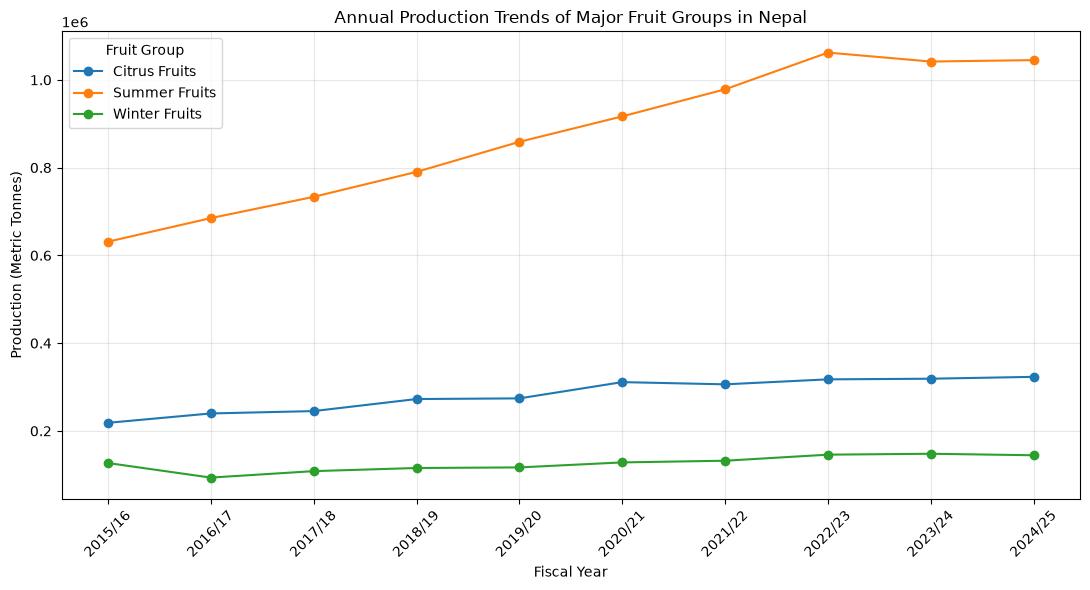

In [49]:
fruit_trend = fruits_analysis.pivot(
    index="Fiscal_Year",
    columns="Fruit_Group",
    values="Production_Mt"
)

plt.figure(figsize=(11, 6))

for fruit in fruit_trend.columns:
    plt.plot(
        fruit_trend.index,
        fruit_trend[fruit],
        marker="o",
        label=fruit
    )

plt.title("Annual Production Trends of Major Fruit Groups in Nepal")
plt.xlabel("Fiscal Year")
plt.ylabel("Production (Metric Tonnes)")
plt.xticks(rotation=45)
plt.legend(title="Fruit Group")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
fruit_summary["Productive_Area_Share_%"] = (
    fruit_summary["Total_Productive_Area_Ha"] /
    fruit_summary["Total_Area_Ha"]
) * 100

display(
    fruit_summary[
        ["Fruit_Group", "Productive_Area_Share_%"]
    ].sort_values("Productive_Area_Share_%", ascending=False)
)

,Fruit_Group,Productive_Area_Share_%
1,Summer Fruits,82.699779
0,Citrus Fruits,63.966814
2,Winter Fruits,54.502607


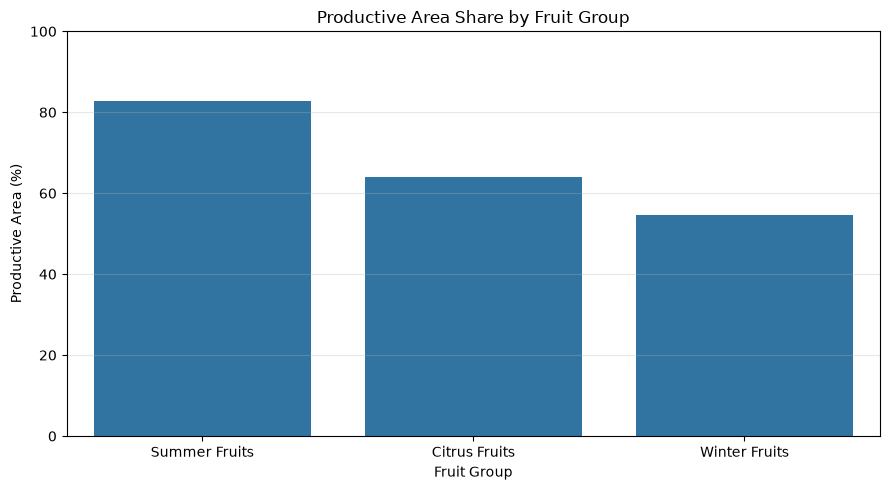

In [51]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=fruit_summary,
    x="Fruit_Group",
    y="Productive_Area_Share_%"
)

plt.title("Productive Area Share by Fruit Group")
plt.xlabel("Fruit Group")
plt.ylabel("Productive Area (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Major Fruits Analysis – Key Findings

- Summer Fruits contributed the highest share of total production (68.15%), followed by Citrus Fruits (22.04%) and Winter Fruits (9.82%).
- Summer Fruits had the highest average yield at 11.12 MT/ha, while Winter Fruits had the lowest at 7.35 MT/ha.
- Summer Fruits recorded the highest productive-area share (82.70%), compared with Citrus Fruits (63.97%) and Winter Fruits (54.50%).
- The annual production trend highlights changes in production across all three fruit groups over the 10-year period.

### Data Scope and Limitations
- Analysis covers three fruit groups from 2015/16 to 2024/25.
- The aggregate `Total Fruits` category was excluded to avoid double-counting.
- Findings represent broad fruit groups, not individual fruit varieties.
- Original source data were preserved without modification.

### Fresh Vegetables